In [ ]:
%pip -q install yfinance pyvinecopulib==1.0.1 numpy pandas scipy matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 3.2 MB/s eta 0:00:00


In [ ]:
# 1. DESCARGA DE COTIZACIONES HISTÓRICAS Y CÁLCULO DE RETORNOS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats, integrate
from itertools import combinations
from pathlib import Path
import zipfile
import ast
import pyvinecopulib as pv

TICKERS = ['GGAL.BA', 'BMA.BA', 'YPFD.BA', 'PAMP.BA']
NOMBRES_ACTIVOS = ['Galicia', 'Banco Macro', 'YPF', 'Pampa Energía']
INICIO_DESCARGA = '2010-01-01'
FIN_DESCARGA_EXCLUSIVO = '2026-09-12'  # Incluye 11/09/2026; fin exclusivo en Yahoo
INICIO_MUESTRA = '2019-01-03'
FIN_MUESTRA = '2026-09-11'

SALIDA = Path('resultados_tesina_librerias')
SALIDA.mkdir(exist_ok=True)
FIG = SALIDA / 'graficos'
FIG.mkdir(exist_ok=True)

cotizaciones = yf.download(
    TICKERS, start=INICIO_DESCARGA, end=FIN_DESCARGA_EXCLUSIVO,
    auto_adjust=False, progress=False, threads=False, actions=False
)
if cotizaciones.empty:
    raise RuntimeError('Yahoo Finance no devolvió datos. Comprobá la conexión y los tickers.')

# Conservamos Adj Close: misma decisión metodológica utilizada en la tesina.
def campo_yahoo(nombre):
    if not isinstance(cotizaciones.columns, pd.MultiIndex):
        raise RuntimeError('Se esperaba la estructura multiactivo de Yahoo Finance.')
    if nombre in cotizaciones.columns.get_level_values(0):
        tabla = cotizaciones[nombre]
    elif nombre in cotizaciones.columns.get_level_values(1):
        tabla = cotizaciones.xs(nombre, axis=1, level=1)
    else:
        raise KeyError(f'No está el campo {nombre} en la descarga. Campos: {cotizaciones.columns.names}')
    faltantes = [t for t in TICKERS if t not in tabla.columns]
    if faltantes:
        raise ValueError(f'Yahoo no entregó datos para los tickers {faltantes}')
    return tabla[TICKERS].rename(columns=dict(zip(TICKERS, NOMBRES_ACTIVOS)))

precios = campo_yahoo('Adj Close').sort_index()
volumen = campo_yahoo('Volume').reindex(precios.index)
cierres = campo_yahoo('Close').reindex(precios.index)
for tabla in (precios, volumen, cierres):
    tabla.index = pd.DatetimeIndex(tabla.index).tz_localize(None)
    tabla.index.name = 'Date'

# Retornos logarítmicos sobre fechas de rueda consecutivas por activo.
# fill_method=None evita fabricar precios a partir de cotizaciones faltantes.
retornos_historicos = np.log(precios / precios.shift(1))
retornos_historicos = retornos_historicos.replace([np.inf, -np.inf], np.nan)

assert precios.index.is_unique and precios.index.is_monotonic_increasing
assert not ((precios <= 0) & precios.notna()).any().any(), 'Precio ajustado no positivo.'
print('Descarga Yahoo:', len(precios), 'fechas:', precios.index.min().date(), 'a', precios.index.max().date())
print('Retornos disponibles por activo (historia completa):')
print(retornos_historicos.count().to_string())

# Archivos opcionales de trazabilidad, generados AHORA, no precargados.
precios.to_csv(SALIDA/'precios_ajustados_yahoo.csv')
cierres.to_csv(SALIDA/'cierres_yahoo.csv')
volumen.to_csv(SALIDA/'volumen_yahoo.csv')
retornos_historicos.to_csv(SALIDA/'retornos_historicos_desde_2010.csv')


Descarga Yahoo: 4074 fechas: 2010-01-04 a 2026-09-11
Retornos disponibles por activo (historia completa):
Ticker
Galicia          4073
Banco Macro      4073
YPF              4073
Pampa Energía    4073


DIAGNÓSTICO ANUAL — historia completa, antes de recortar la muestra


,Año,Acción,Retornos disponibles,Retornos cero (%),Volúmenes disponibles,Volumen cero (%),Período parcial
0,2010,Galicia,244,18.442623,245,11.836735,True
1,2010,Banco Macro,244,18.442623,245,11.836735,True
2,2010,YPF,244,29.508197,245,12.653061,True
3,2010,Pampa Energía,244,20.491803,245,11.836735,True
4,2011,Galicia,244,15.573770,244,11.475410,False
...,...,...,...,...,...,...,...
63,2025,Pampa Energía,243,0.823045,243,0.000000,False
64,2026,Galicia,171,2.339181,171,0.000000,True
65,2026,Banco Macro,171,1.169591,171,0.000000,True
66,2026,YPF,171,0.584795,171,0.000000,True


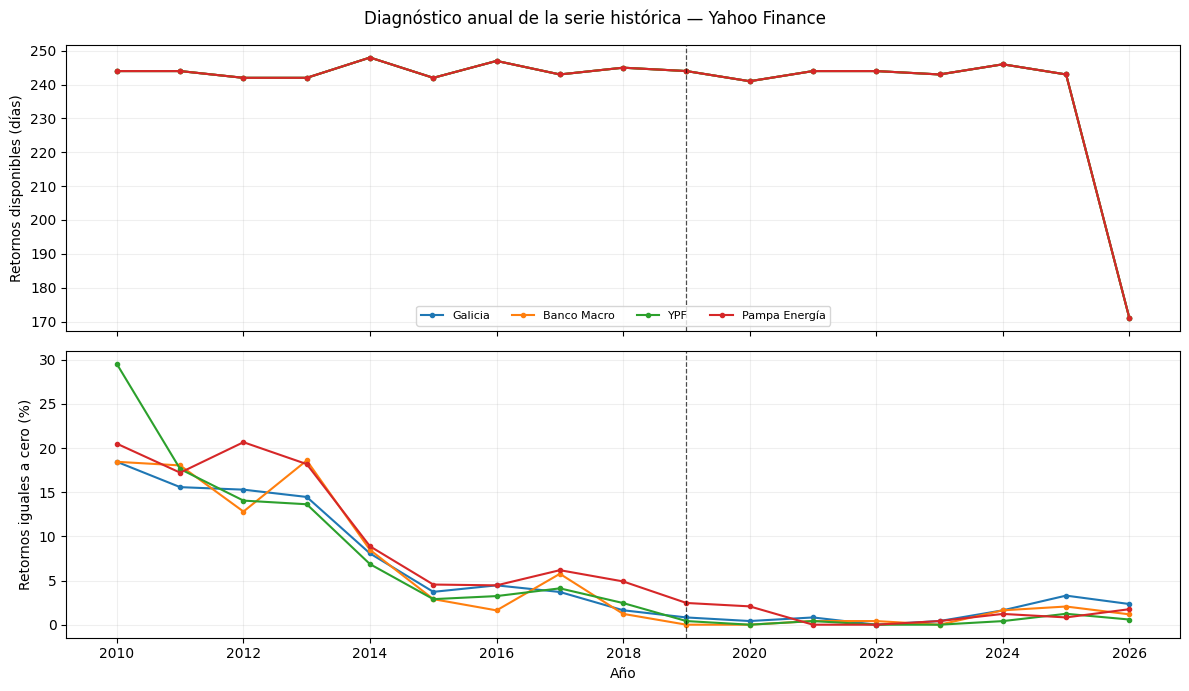

Muestra seleccionada: (1875, 4) desde 2019-01-03 hasta 2026-09-11
Primeras filas de retornos logarítmicos:


Ticker,Date,Galicia,Banco Macro,YPF,Pampa Energía
0,2019-01-03,0.008843,0.010471,0.009495,-0.001996
1,2019-01-04,0.054555,0.036240,0.037940,0.056326
2,2019-01-07,0.030679,0.073575,0.000835,-0.000945
3,2019-01-08,-0.008547,-0.018843,-0.004649,0.016870
4,2019-01-09,0.033758,0.018843,0.003721,0.027499


diagnostico_anual: 68 filas
Biblioteca: 1.0.1
Muestra: 1875 retornos, 2019-01-03 a 2026-09-11


In [ ]:
# 2. DIAGNÓSTICO ANUAL ANTES DE SELECCIONAR LA MUESTRA
# Cada activo puede tener distinto número de días disponibles. Los ceros y
# volúmenes se calculan sobre los valores observados de cada año.
filas = []
for anio in sorted(precios.index.year.unique()):
    for nombre in NOMBRES_ACTIVOS:
        r = retornos_historicos.loc[retornos_historicos.index.year == anio, nombre].dropna()
        v = volumen.loc[volumen.index.year == anio, nombre].dropna()
        if len(r):
            filas.append([anio, nombre, len(r), 100*(r == 0).mean(),
                          len(v), 100*(v == 0).mean(), anio in (2010, 2026)])
ANUAL = pd.DataFrame(filas, columns=[
    'Año','Acción','Retornos disponibles','Retornos cero (%)',
    'Volúmenes disponibles','Volumen cero (%)','Período parcial'
])
print('DIAGNÓSTICO ANUAL — historia completa, antes de recortar la muestra')
display(ANUAL)

# Gráfico del diagnóstico histórico utilizado para examinar disponibilidad.
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for nombre in NOMBRES_ACTIVOS:
    t = ANUAL.loc[ANUAL['Acción'] == nombre].sort_values('Año')
    ax[0].plot(t['Año'], t['Retornos disponibles'], marker='o', ms=3, label=nombre)
    ax[1].plot(t['Año'], t['Retornos cero (%)'], marker='o', ms=3, label=nombre)
ax[0].set_ylabel('Retornos disponibles (días)')
ax[1].set_ylabel('Retornos iguales a cero (%)')
ax[1].set_xlabel('Año')
for a in ax:
    a.grid(alpha=.2)
    a.axvline(2019, color='black', linestyle='--', linewidth=.9, alpha=.7)
ax[0].legend(ncol=4, fontsize=8, loc='lower center')
fig.suptitle('Diagnóstico anual de la serie histórica — Yahoo Finance')
fig.tight_layout()
fig.savefig(FIG/'Diagnostico_anual_historia_completa.png', dpi=180, bbox_inches='tight')
plt.show()

# 3. RECIÉN AHORA: selección de período y construcción de la matriz definitiva
comunes = retornos_historicos.loc[INICIO_MUESTRA:FIN_MUESTRA, NOMBRES_ACTIVOS].dropna(how='any')
D = comunes.rename_axis('Date').reset_index()
X = np.ascontiguousarray(comunes.to_numpy(dtype=float))
if X.shape != (1875, 4):
    print(f'ADVERTENCIA: Yahoo devuelve {X.shape[0]} retornos comunes; la tesina utiliza 1.875.')
    print('No se descartan ni agregan fechas artificialmente. Revisar Yahoo antes de conciliar los cuadros.')
if len(D) == 0:
    raise ValueError('No se pudieron construir retornos comunes para el período de estudio.')
print('Muestra seleccionada:', X.shape, 'desde', D.Date.iloc[0].date(), 'hasta', D.Date.iloc[-1].date())
print('Primeras filas de retornos logarítmicos:')
display(D.head())

PARES = list(combinations(range(4), 2))
NOMBRES = ['Galicia–Macro', 'Galicia–YPF', 'Galicia–Pampa',
           'Macro–YPF', 'Macro–Pampa', 'YPF–Pampa']
FAM = ['Gaussiana', 't-Student', 'Clayton', 'Gumbel',
       'Gumbel-supervivencia', 'Joe-Clayton']
NIVELES = [.95, .975, .99]
Q = np.arange(.02, .101, .01).round(2)
M = 1_000_000
SEMILLA = 20261014
SALIDA = Path('resultados_tesina_librerias')
SALIDA.mkdir(exist_ok=True)
FIG = SALIDA / 'graficos'
FIG.mkdir(exist_ok=True)

FAMILIAS = {
    'Gaussiana': (pv.families.gaussian, 0),
    't-Student': (pv.families.student, 0),
    'Clayton': (pv.families.clayton, 0),
    'Gumbel': (pv.families.gumbel, 0),
    'Gumbel-supervivencia': (pv.families.gumbel, 180),
    'Joe-Clayton': (pv.families.bb7, 0),
}

def guardar(nombre, df):
    df.to_csv(SALIDA / f'{nombre}.csv', index=False, encoding='utf-8-sig')
    print(f'{nombre}: {len(df)} filas')

# Las pseudoobservaciones son los rangos promedio divididos por (n+1).
def rangos(x):
    return np.ascontiguousarray(stats.rankdata(x, axis=0, method='average') / (len(x) + 1), dtype=float)

def ajustar_copula(u, familia):
    tipo, rotacion = FAMILIAS[familia]
    modelo = pv.Bicop(family=tipo, rotation=rotacion)
    modelo.fit(u=u)                   # Ajuste de máxima pseudoverosimilitud
    return modelo

def cdf_modelo(modelo, u, v):
    uv = np.array([[float(u), float(v)]], dtype=np.float64)
    return float(np.asarray(modelo.cdf(uv)).reshape(-1)[0])

def colas_teoricas(familia, p):
    # Fórmulas de coeficientes asintóticos; no se programan densidades ni inversas.
    if familia == 'Gaussiana': return 0., 0.
    if familia == 't-Student':
        rho, nu = p
        li = 2 * stats.t.cdf(-np.sqrt((nu + 1) * (1 - rho) / (1 + rho)), nu + 1)
        return li, li
    if familia == 'Clayton': return 2**(-1/p[0]), 0.
    if familia == 'Gumbel': return 0., 2 - 2**(1/p[0])
    if familia == 'Gumbel-supervivencia': return 2 - 2**(1/p[0]), 0.
    return 2**(-1/p[1]), 2 - 2**(1/p[0])

D.to_csv(SALIDA / 'retornos_comunes.csv', index=False)
guardar('diagnostico_anual', ANUAL)
print('Biblioteca:', pv.__version__)
print('Muestra:', len(D), 'retornos,', D.Date.iloc[0].date(), 'a', D.Date.iloc[-1].date())

In [ ]:
# 1. Ajuste y medidas de concentración con pyvinecopulib
PROPIEDADES = pd.DataFrame([
    ['Gaussiana','rho','No','No','Simétrica, sin dependencia asintótica'],
    ['t-Student','rho, nu','Sí','Sí','Simétrica en ambas colas'],
    ['Clayton','theta','Sí','No','Orientada a la inferior'],
    ['Gumbel','theta','No','Sí','Orientada a la superior'],
    ['Gumbel-supervivencia','theta','Sí','No','Rotación de Gumbel'],
    ['Joe-Clayton','theta, delta','Sí','Sí','Asimetría flexible']],
    columns=['familia','parametros','cola_inferior','cola_superior','caracteristica'])
guardar('Cuadro_1_propiedades', PROPIEDADES)

modelos = {}
ajustes, curvas, descriptivos, asociacion, joint = [], [], [], [], []
for j, nombre in enumerate(NOMBRES_ACTIVOS):
    x = X[:, j]
    descriptivos.append([nombre, 100*x.mean(), 100*x.std(ddof=1),
                         stats.skew(x,bias=False), stats.kurtosis(x,bias=False)])
for k, (i, j) in enumerate(PARES):
    x, par = X[:, [i,j]], NOMBRES[k]
    u = rangos(x)
    asociacion.append([par, np.corrcoef(x.T)[0,1],
        stats.kendalltau(x[:,0],x[:,1]).statistic,
        100*np.mean((u[:,0]<=.05)&(u[:,1]<=.05))/.05,
        100*np.mean((u[:,0]>=.95)&(u[:,1]>=.95))/.05])
    for familia in FAM:
        modelo = ajustar_copula(u, familia)
        modelos[(par, familia)] = modelo
        p = np.asarray(modelo.parameters, float).reshape(-1)
        ll = float(modelo.loglik(u))
        li, ls = colas_teoricas(familia, p)
        ajustes.append([par, f'{i}_{j}', familia, repr(p.tolist()), ll,
                        float(modelo.aic(u)), float(modelo.bic(u)), li, ls])
        for q in Q:
            emp = np.mean((u[:,0] <= q) & (u[:,1] <= q)) / q
            mod = cdf_modelo(modelo, q, q) / q
            curvas.append([par, familia, q, emp, mod, 100*(emp-mod)])
        for umbral in [.05, .10]:
            p_simple = np.log1p(-umbral)
            a = np.mean(x[:,0] <= p_simple)
            b = np.mean(x[:,1] <= p_simple)
            joint.append([par, familia, umbral, cdf_modelo(modelo, a, b)])
    print('Ajustado:',par)

AJ = pd.DataFrame(ajustes, columns=['par','id','familia','parametros','loglik','AIC','BIC','lambda_inf','lambda_sup'])
CU = pd.DataFrame(curvas, columns=['par','familia','q','empirica','modelo','diferencia_pp'])
DES = pd.DataFrame(descriptivos, columns=['activo','media_pct','desvio_pct','asimetria','curtosis_exceso'])
ASO = pd.DataFrame(asociacion, columns=['par','pearson','kendall_tau_b','inferior_5_pct','superior_5_pct'])
JO = pd.DataFrame(joint, columns=['par','familia','umbral','probabilidad'])

# Cola superior: P(U>1-q,V>1-q) / q.
SUP = []
for k, (i, j) in enumerate(PARES):
    u, par = rangos(X[:,[i,j]]), NOMBRES[k]
    for familia in FAM:
        modelo = modelos[(par,familia)]
        for q in Q:
            emp = np.mean((u[:,0]>=1-q) & (u[:,1]>=1-q)) / q
            mod = (2*q - 1 + cdf_modelo(modelo,1-q,1-q)) / q
            SUP.append([par,familia,q,emp,mod,100*(emp-mod)])
SU = pd.DataFrame(SUP, columns=['par','familia','q','empirica','modelo','diferencia_pp'])
RES = SU.groupby(['par','familia']).diferencia_pp.agg(lambda a: np.sqrt(np.mean(a**2))).reset_index(name='RECM_superior_pp')
RE  = CU.groupby(['par','familia']).diferencia_pp.agg(lambda a: np.sqrt(np.mean(a**2))).reset_index(name='RECM_pp')
EMJO=[]
for k,(i,j) in enumerate(PARES):
    for umbral in [.05,.10]:
        shock = np.log1p(-umbral)
        EMJO.append([NOMBRES[k],umbral,100*np.mean((X[:,i]<=shock)&(X[:,j]<=shock))])
EMJO=pd.DataFrame(EMJO,columns=['par','umbral','empirica_pct'])

for nombre,tabla in [('Cuadro_2',DES),('Cuadro_3',ASO),('Cuadros_4_y_5_ajustes',AJ),
                     ('Cuadros_6_y_7_concentraciones',CU),('Cuadro_6B_concentraciones_superiores',SU),
                     ('Cuadro_7_RECM',RE),('Cuadro_7B_RECM_superior',RES),
                     ('Cuadro_8_prob_conjuntas',JO),('Cuadro_8_empiricas',EMJO)]:
    guardar(nombre,tabla)

Cuadro_1_propiedades: 6 filas
Ajustado: Galicia–Macro
Ajustado: Galicia–YPF
Ajustado: Galicia–Pampa
Ajustado: Macro–YPF
Ajustado: Macro–Pampa
Ajustado: YPF–Pampa
Cuadro_2: 4 filas
Cuadro_3: 6 filas
Cuadros_4_y_5_ajustes: 36 filas
Cuadros_6_y_7_concentraciones: 324 filas
Cuadro_6B_concentraciones_superiores: 324 filas
Cuadro_7_RECM: 36 filas
Cuadro_7B_RECM_superior: 36 filas
Cuadro_8_prob_conjuntas: 72 filas
Cuadro_8_empiricas: 12 filas


In [ ]:
# 2. Monte Carlo con NumPy y la inversa condicional de pyvinecopulib
# Se conservan la interpolación marginal y las pérdidas de cartera de la tesina.
def cuantil_marginal(x, u):
    y = np.sort(x)
    n = len(y)
    return np.interp(u, np.arange(1,n+1)/(n+1), y, left=y[0], right=y[-1])

def perdidas(x, modelo, z):
    v = np.asarray(modelo.hinv1(np.ascontiguousarray(z, dtype=float)),float).reshape(-1)
    r1 = cuantil_marginal(x[:,0],z[:,0])
    r2 = cuantil_marginal(x[:,1],v)
    return -.5*(np.expm1(r1)+np.expm1(r2))

def riesgo(loss):
    ordenadas=np.sort(loss)
    n=len(ordenadas)
    return np.array([[np.quantile(ordenadas, a),ordenadas[-round(n*(1-a)):].mean()]
                     for a in NIVELES])

RIESGO, PREC, SEN, B1 = [], [], [], []
for k,(i,j) in enumerate(PARES):
    par = NOMBRES[k]
    x = X[:,[i,j]]
    z = np.random.default_rng(SEMILLA+100*k).random((M,2))
    por_familia, grupos = {}, {}
    for familia in FAM:
        loss=perdidas(x, modelos[(par,familia)], z)
        por_familia[familia]=riesgo(loss)
        grupos[familia]=np.stack([riesgo(g) for g in np.array_split(loss,5)])
        for alpha,(var,tvar) in zip(NIVELES,por_familia[familia]):
            RIESGO.append([par,familia,alpha,var,tvar])
        PREC.append([par,familia,100*grupos[familia][:,2,0].std(ddof=1),
                     100*grupos[familia][:,2,1].std(ddof=1)])
    for familia in ['t-Student','Joe-Clayton']:
        referencia='Gaussiana' if familia=='t-Student' else 'Gumbel-supervivencia'
        delta=100*(grupos[familia][:,2,1]-grupos[referencia][:,2,1])
        B1.append([par,familia+' - '+referencia,
                   100*(por_familia[familia][2,1]-por_familia[referencia][2,1]),
                   delta.min(),delta.max()])
    # Sensibilidad: reestimación con la misma biblioteca y muestra sin el 12/08/2019.
    xx=x[D.Date.to_numpy()!=np.datetime64('2019-08-12')]
    for familia in ['Gaussiana','t-Student','Clayton']:
        alternativo=ajustar_copula(rangos(xx),familia)
        tvar99=riesgo(perdidas(xx,alternativo,z))[2,1]
        SEN.append([par,familia,100*por_familia[familia][2,1],100*tvar99])
    print('Simulado:',par)

R=pd.DataFrame(RIESGO,columns=['par','familia','alpha','VaR','TVaR'])
PREC=pd.DataFrame(PREC,columns=['par','familia','sd_VaR99_pp','sd_TVaR99_pp'])
B1=pd.DataFrame(B1,columns=['par','comparacion','delta_TVaR99_pp','min_grupos_pp','max_grupos_pp'])
SEN=pd.DataFrame(SEN,columns=['par','familia','TVaR99_total_pct','TVaR99_sin_dia_pct'])
GAUSS=R[R.familia=='Gaussiana'].set_index(['par','alpha'])
DEL=[]
for row in R.itertuples():
    g=GAUSS.loc[(row.par,row.alpha)]
    DEL.append([row.par,row.familia,row.alpha,100*(row.VaR-g.VaR),100*(row.TVaR-g.TVaR)])
DE=pd.DataFrame(DEL,columns=['par','familia','alpha','delta_VaR_pp','delta_TVaR_pp'])

def marginal_tvar(x):
    q=np.linspace(0,.01,200001)
    return integrate.trapezoid(-np.expm1(cuantil_marginal(x,q)),q)/.01

tmar=[marginal_tvar(X[:,i]) for i in range(4)]
DIV=[]
for k,(i,j) in enumerate(PARES):
    par=NOMBRES[k]; prom=.5*(tmar[i]+tmar[j])
    g=R.query('par == @par and familia == "Gaussiana" and alpha == .99').iloc[0].TVaR
    for familia in FAM:
        tv=R.query('par == @par and familia == @familia and alpha == .99').iloc[0].TVaR
        delta=100*(tv-g)
        b_gauss=round(100*(prom-g),2)
        DIV.append([par,familia,100*(prom-tv),delta,100*delta/b_gauss])
DIV=pd.DataFrame(DIV,columns=['par','familia','beneficio_pp','erosion_pp','erosion_pct'])

def tvar_historico(loss,alpha=.99):
    s=np.sort(loss);cola=len(s)*(1-alpha);n=int(np.floor(cola));resto=cola-n
    return (s[-n:].sum()+resto*s[-n-1])/cola
HIST=[]
for k,(i,j) in enumerate(PARES):
    for quitar in [False,True]:
        x=X[:,[i,j]] if not quitar else X[D.Date.to_numpy()!=np.datetime64('2019-08-12')][:,[i,j]]
        loss=-.5*(np.expm1(x[:,0])+np.expm1(x[:,1]))
        HIST.append([NOMBRES[k],'Sin 12/08/2019' if quitar else 'Completa',
                     100*np.quantile(loss,.99),100*tvar_historico(loss)])
HIST=pd.DataFrame(HIST,columns=['par','muestra','VaR99_pct','TVaR99_pct'])
E1=pd.DataFrame([['Galicia',174.55,92.40],['Banco Macro',350.85,187.65],
                 ['YPF',760.00,631.45],['Pampa Energía',63.50,35.00]],
                columns=['activo','cierre_09_08_2019','cierre_12_08_2019'])
E1['retorno_simple_pct']=100*(E1.cierre_12_08_2019/E1.cierre_09_08_2019-1)

for nombre,tabla in [('Cuadro_9_y_D1_VaR_TVaR',R),('Cuadros_10_y_11_diferencias',DE),
                     ('Cuadro_12_y_D2_diversificacion',DIV),('Cuadro_B1_precision',B1),
                     ('Cuadro_E1_precios_historicos',E1),('Cuadro_E2_sensibilidad',SEN),
                     ('Cuadro_E3_riesgo_historico',HIST)]:
    guardar(nombre,tabla)

Simulado: Galicia–Macro
Simulado: Galicia–YPF
Simulado: Galicia–Pampa
Simulado: Macro–YPF
Simulado: Macro–Pampa
Simulado: YPF–Pampa
Cuadro_9_y_D1_VaR_TVaR: 108 filas
Cuadros_10_y_11_diferencias: 108 filas
Cuadro_12_y_D2_diversificacion: 36 filas
Cuadro_B1_precision: 12 filas
Cuadro_E1_precios_historicos: 4 filas
Cuadro_E2_sensibilidad: 18 filas
Cuadro_E3_riesgo_historico: 12 filas


In [ ]:
# Gráficos con ejes y unidades identificados
NAMES = list(D.columns[1:])
PAIRS = PARES
PARNAMES = NOMBRES
short = {'Gaussiana':'Gaussiana','t-Student':'t de Student','Clayton':'Clayton',
         'Gumbel':'Gumbel','Gumbel-supervivencia':'Gumbel de supervivencia','Joe-Clayton':'Joe-Clayton'}
plt.rcParams.update({'font.size':10,'axes.labelsize':10,'axes.titlesize':10,'xtick.labelsize':8.5,'ytick.labelsize':8.5,'legend.fontsize':8.5,'savefig.dpi':180})

def figura(nombre,fig,rect=None):
    if rect:fig.tight_layout(rect=rect)
    else:fig.tight_layout()
    fig.savefig(FIG/f'{nombre}.png',dpi=180,bbox_inches='tight',facecolor='white')
    plt.close(fig)

fig,axs=plt.subplots(2,2,figsize=(12,6.5))
for i,a in enumerate(axs.flat):
    a.plot(D.Date,100*X[:,i],lw=.65)
    a.set(title=NAMES[i],xlabel='Fecha',ylabel='Retorno logarítmico diario (%)')
    a.grid(alpha=.18)
    a.tick_params(axis='x',rotation=0)
figura('Grafico_1_retornos',fig)

fig,axs=plt.subplots(2,2,figsize=(10.5,7.5))
for i,a in enumerate(axs.flat):
    x=(X[:,i]-X[:,i].mean())/X[:,i].std(ddof=1)
    (osm,osr),(slope,intercept,r)=stats.probplot(x,dist='norm')
    a.scatter(osm,osr,s=10,alpha=.7)
    a.plot(osm,intercept+slope*np.asarray(osm),linestyle='--',linewidth=1)
    a.set(title=NAMES[i],xlabel='Cuantiles teóricos N(0,1)',ylabel='Cuantiles empíricos estandarizados')
    a.grid(alpha=.17)
figura('Grafico_2_cuantiles_normales',fig)

fig,axs=plt.subplots(3,2,figsize=(10.5,11.5))
for k,(i,j) in enumerate(PAIRS):
    u=stats.rankdata(X[:,[i,j]],axis=0,method='average')/(len(X)+1)
    a=axs.flat[k]
    a.scatter(u[:,0],u[:,1],s=3,alpha=.30)
    a.set(title=PARNAMES[k],xlim=(0,1),ylim=(0,1),xlabel=f'Pseudoobservación: {NAMES[i]}',ylabel=f'Pseudoobservación: {NAMES[j]}')
    a.grid(alpha=.10)
figura('Grafico_3_pseudoobservaciones',fig)

reg=np.linspace(.01,.99,70);u,v=np.meshgrid(reg,reg);uv=np.column_stack([u.ravel(),v.ravel()])
fig,axs=plt.subplots(2,3,figsize=(12,7.4));levels=np.linspace(0,18,17)
for a,f in zip(axs.flat,FAM):
    par=AJ[(AJ['par']=='Galicia–Macro')&(AJ['familia']==f)].iloc[0]
    modelo = modelos[('Galicia–Macro',f)]
    zz=np.clip(np.asarray(modelo.pdf(np.ascontiguousarray(uv, dtype=float)),float),0,18).reshape(u.shape)
    co=a.contourf(u,v,zz,levels=levels,vmin=0,vmax=18)
    a.set(title=short[f],xlabel='Pseudoobservación: Galicia',ylabel='Pseudoobservación: Macro')
    a.tick_params(labelsize=8)
fig.subplots_adjust(left=.10,right=.84,bottom=.10,top=.93,wspace=.45,hspace=.44)
cax=fig.add_axes([.875,.18,.022,.64])
fig.colorbar(co,cax=cax,label='Densidad de cópula c(u, v)')
fig.savefig(FIG/'Grafico_4_densidades_Galicia_Macro.png',dpi=180,bbox_inches='tight',facecolor='white')
plt.close(fig)

for filename,is_diff in [('Grafico_5_concentraciones',False),('Grafico_6_discrepancias',True),('Grafico_A1_discrepancias',True)]:
    fig,axs=plt.subplots(3,2,figsize=(12,12.2))
    for ax,par in zip(axs.flat,PARNAMES):
        g=CU[CU.par==par]
        if not is_diff:
            t=g[g.familia=='Gaussiana'].sort_values('q')
            ax.plot(100*t.q,100*t.empirica,'k-',lw=2.1,label='Empírica',zorder=10)
        for f in FAM:
            t=g[g.familia==f].sort_values('q')
            y=t.diferencia_pp if is_diff else 100*t.modelo
            ax.plot(100*t.q,y,lw=1.3,label=short[f])
        if is_diff:ax.axhline(0,color='gray',linewidth=.75)
        ax.set(title=par,xlabel='Umbral de cola q (%)',
               ylabel='Discrepancia: empírica − modelo (pp)' if is_diff else 'Concentración inferior (%)')
        ax.set_xlim(1.8,10.2)
        ax.set_xticks([2,4,6,8,10]);ax.grid(alpha=.15)
    handles,labels=axs.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',ncol=4,frameon=False,fontsize=9,bbox_to_anchor=(.5,.012))
    figura(filename,fig,rect=[0,.09,1,1])

m=DE[DE.familia!='Gaussiana'].groupby(['familia','alpha']).delta_TVaR_pp.mean()
fig,ax=plt.subplots(figsize=(9,5))
for f in FAM[1:]:
    ax.plot([95,97.5,99],m[f].values,marker='o',label=short[f])
ax.axhline(0,color='gray',lw=.8)
ax.set(xlabel='Nivel de confianza (%)',ylabel='ΔTVaR medio frente a la gaussiana (pp)')
ax.legend(ncol=2,fontsize=9);ax.grid(alpha=.13)
figura('Grafico_7_delta_TVaR_por_nivel',fig)

fig,ax=plt.subplots(figsize=(10,6))
for f in FAM:
    xa=[];ya=[]
    for par in PARNAMES:
        r=CU[(CU.par==par)&(CU.familia==f)&np.isclose(CU.q,.05)].iloc[0]
        xa.append(100*(r.modelo-r.empirica))
        ya.append(DE[(DE.par==par)&(DE.familia==f)&np.isclose(DE.alpha,.99)].iloc[0].delta_TVaR_pp)
    ax.scatter(xa,ya,label=short[f],s=44)
ax.axhline(0,color='gray',lw=.6);ax.axvline(0,color='gray',lw=.6)
ax.set(xlabel='Concentración modelada − empírica al 5 % (pp)',ylabel='ΔTVaR al 99 % frente a la gaussiana (pp)')
ax.legend(ncol=2,fontsize=9);ax.grid(alpha=.12)
figura('Grafico_8_discrepancia_y_TVaR',fig)

fig,axs=plt.subplots(2,1,figsize=(11,7.4),sharex=True)
for nombre,g in ANUAL.groupby('Acción'):
    axs[0].plot(g['Año'],g['Retornos cero (%)'],marker='.',label=nombre)
    axs[1].plot(g['Año'],g['Volumen cero (%)'],marker='.',label=nombre)
for a in axs:
    a.axvline(2019,color='gray',ls='--',lw=.9)
    a.grid(alpha=.15);a.legend(ncol=4,fontsize=9)
axs[0].set_ylabel('Retornos diarios iguales a cero (%)')
axs[1].set_ylabel('Observaciones con volumen cero (%)')
axs[1].set_xlabel('Año')
figura('Grafico_C1_calidad_historica',fig)

# Cuadro A1, menor discrepancia absoluta en cada umbral.
A1=[]
for par in NOMBRES:
    A1.append([par]+[CU[(CU.par==par)&(CU.q==q)].iloc[CU[(CU.par==par)&(CU.q==q)].diferencia_pp.abs().argmin()].familia for q in [.02,.05,.10]])
guardar('Cuadro_A1_mejor_por_umbral',pd.DataFrame(A1,columns=['par','q_2_pct','q_5_pct','q_10_pct']))

print('Gráficos finalizados:',len(list(FIG.glob('*.png'))))

Cuadro_A1_mejor_por_umbral: 6 filas
Gráficos finalizados: 11


In [ ]:
# 7. EXPORTACIÓN: todos los resultados se calcularon en esta ejecución.
with zipfile.ZipFile('resultados_tesina_librerias.zip','w',compression=zipfile.ZIP_DEFLATED) as z:
    for ruta in SALIDA.rglob('*'):
        if ruta.is_file(): z.write(ruta,arcname=str(ruta.relative_to(SALIDA)))
print('Terminado: resultados_tesina_librerias.zip')
try:
    from google.colab import files
    files.download('resultados_tesina_librerias.zip')
except ImportError:
    pass

Terminado: resultados_tesina_librerias.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>